In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Train-Test Split
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder,OneHotEncoder

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [38]:
df = pd.read_csv('churn_clean_Data.csv')

In [3]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
1,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
2,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
3,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
4,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7672,9994,15569266,Rahman,644,France,Male,28,7,155060.41,1,1,0,29179.52,0
7673,9995,15719294,Wood,800,France,Female,29,2,0.00,2,0,0,167773.55,0
7674,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
7675,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0


In [5]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
1,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
2,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
3,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
4,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0


In [40]:
print(df.shape)
print(df['Exited'].unique())
print(df['Exited'].value_counts())

(9940, 14)
[1 0]
Exited
0    7963
1    1977
Name: count, dtype: int64


In [41]:
df.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9935,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9936,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9937,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9938,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9939,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [42]:
df.shape

(9940, 14)

In [43]:
df.dtypes

RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [44]:
df.duplicated().sum()

np.int64(0)

In [45]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [46]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,9940.000000,9.940000e+03,9940.000000,9940.000000,9940.000000,9940.000000,9940.000000,9940.000000,9940.000000,9940.000000,9940.000000
mean,4999.445573,1.569103e+07,650.510362,38.880986,5.011066,76381.781165,1.515292,0.705634,0.515292,100062.029719,0.198893
std,2887.982110,7.195305e+04,96.629832,10.485202,2.891901,62413.956216,0.550743,0.455780,0.499791,57512.137709,0.399188
min,1.000000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,2496.750000,1.562860e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,51002.110000,0.000000
50%,5001.500000,1.569101e+07,652.000000,37.000000,5.000000,97038.690000,1.000000,1.000000,1.000000,100129.330000,0.000000
75%,7499.250000,1.575336e+07,718.000000,44.000000,7.000000,127611.332500,2.000000,1.000000,1.000000,149401.645000,0.000000
max,10000.000000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,3.000000,1.000000,1.000000,199992.480000,1.000000


In [47]:
df.corr(numeric_only = True)

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,1.000000,0.004141,0.005279,0.000562,-0.007356,-0.008529,0.006049,0.000704,0.012215,-0.005958,-0.017547
CustomerId,0.004141,1.000000,0.005875,0.010866,-0.014648,-0.011431,0.023447,-0.015034,0.000309,0.015580,-0.003930
CreditScore,0.005279,0.005875,1.000000,-0.004826,0.001204,0.005171,0.012145,-0.004884,0.026329,-0.000988,-0.027891
Age,0.000562,0.010866,-0.004826,1.000000,-0.010505,0.027863,-0.050169,-0.011942,0.085833,-0.007797,0.281880
Tenure,-0.007356,-0.014648,0.001204,-0.010505,1.000000,-0.012815,0.011581,0.022242,-0.030050,0.007139,-0.015416
Balance,-0.008529,-0.011431,0.005171,0.027863,-0.012815,1.000000,-0.330632,-0.014836,-0.009919,0.013454,0.116938
NumOfProducts,0.006049,0.023447,0.012145,-0.050169,0.011581,-0.330632,1.000000,0.004707,0.011944,0.012878,-0.105594
HasCrCard,0.000704,-0.015034,-0.004884,-0.011942,0.022242,-0.014836,0.004707,1.000000,-0.011597,-0.009438,-0.006657
IsActiveMember,0.012215,0.000309,0.026329,0.085833,-0.030050,-0.009919,0.011944,-0.011597,1.000000,-0.011451,-0.157712
EstimatedSalary,-0.005958,0.015580,-0.000988,-0.007797,0.007139,0.013454,0.012878,-0.009438,-0.011451,1.000000,0.011294


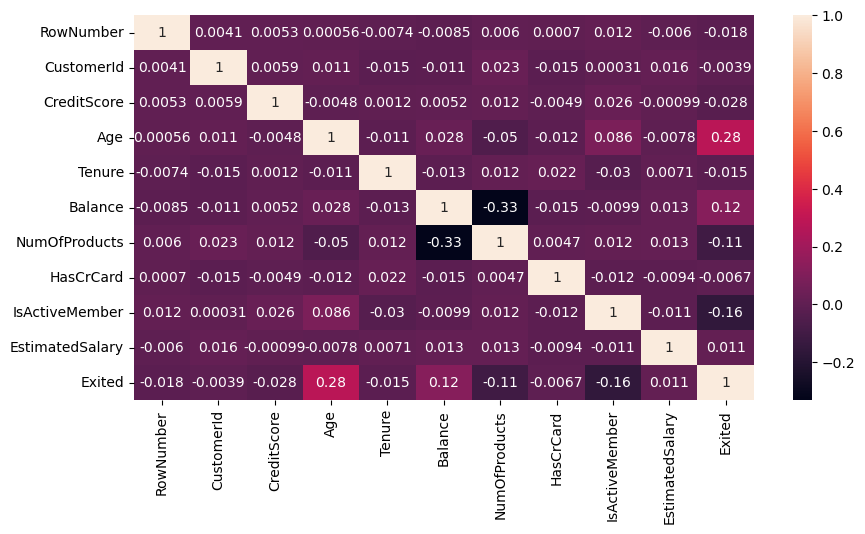

In [48]:
plt.figure(figsize=(10,5))
sns.heatmap(df.corr(numeric_only = True),annot =True)
plt.show()

### Splitting the data for the input and output

In [49]:
print(df['Exited'].value_counts())

Exited
0    7963
1    1977
Name: count, dtype: int64


In [50]:
x = df.drop(columns = 'Exited')
x.head()

y = df['Exited']
y.head()

0    1
1    0
2    1
3    0
4    0
Name: Exited, dtype: int64

In [51]:
x.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [52]:
x.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary'],
      dtype='object')

In [53]:
x.drop(columns = ['RowNumber', 'CustomerId', 'Surname'],inplace=True)

In [54]:
x.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [55]:
X_df = x.copy()

### Encoding the categorical data

In [56]:
le = LabelEncoder()

In [57]:
x['Geography']=le.fit_transform(x['Geography'])

In [58]:
x['Gender']=le.fit_transform(x['Gender'])

In [59]:
x.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,0,0,42,2,0.00,1,1,1,101348.88
1,608,2,0,41,1,83807.86,1,0,1,112542.58
2,502,0,0,42,8,159660.80,3,1,0,113931.57
3,699,0,0,39,1,0.00,2,0,0,93826.63
4,850,2,0,43,2,125510.82,1,1,1,79084.10


### Feature scaling

In [60]:
ss = StandardScaler()

In [61]:
x_scaled = ss.fit_transform(x)

In [62]:
x_scaled

array([[-0.32610992, -0.9018904 , -1.09837939, ...,  0.64588363,
         0.96987019,  0.02237641],
       [-0.43995213,  1.51286801, -1.09837939, ..., -1.54826651,
         0.96987019,  0.21701816],
       [-1.53697704, -0.9018904 , -1.09837939, ...,  0.64588363,
        -1.03106582,  0.24117062],
       ...,
       [ 0.60532631, -0.9018904 , -1.09837939, ..., -1.54826651,
         0.96987019, -1.008124  ],
       [ 1.25733168,  0.3054888 ,  0.91043223, ...,  0.64588363,
        -1.03106582, -0.12473664],
       [ 1.46431751, -0.9018904 , -1.09837939, ...,  0.64588363,
        -1.03106582, -1.07584876]], shape=(9940, 10))

### Splitting the data for the training and testing

In [63]:
X_train,X_test,Y_train,Y_test = train_test_split(x_scaled,y,test_size=0.2)

In [64]:
X_train.shape,X_test.shape,Y_train.shape,Y_test.shape

((7952, 10), (1988, 10), (7952,), (1988,))

# Model Building

### Logistic Regression

In [65]:
log_Reg = LogisticRegression()

In [66]:
log_Reg.fit(X_train,Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [68]:
y_pred = log_Reg.predict(X_test)

In [69]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(1988,))

In [70]:
Y_test

6632    0
3021    0
7262    0
9609    0
3594    0
       ..
3145    1
1870    1
6774    0
1624    1
3654    0
Name: Exited, Length: 1988, dtype: int64

In [71]:
accuracy = accuracy_score(Y_test,y_pred)

In [72]:
accuracy

0.8138832997987927

In [73]:
print(classification_report(Y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      0.97      0.89      1596
           1       0.59      0.19      0.29       392

    accuracy                           0.81      1988
   macro avg       0.71      0.58      0.59      1988
weighted avg       0.78      0.81      0.77      1988



### Decision Tree CLassifier

In [74]:
Dtc = DecisionTreeClassifier()

In [75]:
Dtc.fit(X_train,Y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [76]:
y_pred_dt = Dtc.predict(X_test)

In [77]:
accuracy_dt_test = accuracy_score(Y_test,y_pred_dt)
accuracy_dt_test

0.8048289738430584

In [78]:
#checking the accuract for the training
y_pred_dt_train = Dtc.predict(X_train)
accuracy_dt_train = accuracy_score(y_pred_dt_train,Y_train)
accuracy_dt_train

1.0

### Navie Bayers

In [79]:
NB= GaussianNB()

In [80]:
NB.fit(X_train,Y_train)

,priors,None
,var_smoothing,1e-09


In [81]:
y_pred_train = NB.predict(X_train)
acc_train = accuracy_score(Y_train,y_pred_train)
acc_train

0.8248239436619719

In [82]:
#checking the accuract for the training
y_pred_test = NB.predict(X_test)
acc_test = accuracy_score(y_pred_test,Y_test)
acc_test

0.8269617706237424

### KNN

In [84]:
from sklearn.neighbors import KNeighborsClassifier

In [85]:
KNN= KNeighborsClassifier(n_neighbors=5)

In [87]:
KNN.fit(X_train,Y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [88]:
y_pred_train = KNN.predict(X_train)
acc_train = accuracy_score(Y_train,y_pred_train)
acc_train

0.8780181086519114

In [89]:
#checking the accuract for the training
y_pred_test = KNN.predict(X_test)
acc_test = accuracy_score(y_pred_test,Y_test)
acc_test

0.8274647887323944

#### Pipeline

In [93]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [94]:
cat_cols = [
    "Geography",
    "Gender"
]

In [95]:
num_cols = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
]

In [96]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(), cat_cols)
    ]
)

In [97]:
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(class_weight="balanced"))
])

In [98]:
X_df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10
...,...,...,...,...,...,...,...,...,...,...
9935,771,France,Male,39,5,0.00,2,1,0,96270.64
9936,516,France,Male,35,10,57369.61,1,1,1,101699.77
9937,709,France,Female,36,7,0.00,1,0,1,42085.58
9938,772,Germany,Male,42,3,75075.31,2,1,0,92888.52


In [99]:
X_train1,X_test1,Y_train1,Y_test1 = train_test_split(X_df,y,test_size=0.2)

In [100]:
pipeline.fit(X_train1, Y_train1)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [101]:
y_pred_pipe = pipeline.predict(X_test1)

In [102]:
accu_pipe = accuracy_score(y_pred_pipe,Y_test1)

In [103]:
accu_pipe

0.71579476861167

In [108]:
Cust_1 = pd.DataFrame({

    "CreditScore":[619],
    "Geography":["France"],
    "Gender":["Female"],
    "Age":[42],
    "Tenure":[2],
    "Balance":[0.00],
    "NumOfProducts":[1],
    "HasCrCard":[1],
    "IsActiveMember":[1],
    "EstimatedSalary":[101348.88]

})

In [111]:
print(pipeline.predict(Cust_1))

[0]


In [110]:
pipeline.predict_proba(Cust_1)

array([[0.58171769, 0.41828231]])

In [113]:
import joblib

In [114]:
joblib.dump(pipeline,"churn_pipeline.pkl")

['churn_pipeline.pkl']